# A New Look at the Response Surface Approach for Reliability Analysis: the Undamped Yielding Oscillator

__Malur R. Rajashekhar__, Department of Civil Engineering, The Johns Hopkins University, Baltimore MD 21218-2699, USA

__Bruce R. Ellingwood__, Department of Civil Engineering, The Johns Hopkins University, Baltimore MD 21218-2699, USA

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

This notebook studies Example 2 of [[1]](https://doi.org/10.1016/0167-4730(93)90003-J) (Sec. 4.2, pp. 217–219), the limit state of an undamped single-degree-of-freedom oscillator with a yielding spring under a rectangular pulse load (Fig. 10, p. 217). The oscillator is solved exactly, event by event, in numpy; the closed-form *linear* version that later became a standard reliability benchmark (the `UndampedOscillator` function of UQTestFuns [[3]](https://doi.org/10.21105/joss.05671)) is kept as a secondary study. It runs in Python 3 with numpy, scipy and matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, and takes about one minute, most of it the Monte Carlo estimates of the failure probability (the last cell prints the run time).

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import oscillator_model as om

SEED = 1993                       # the only seed in this notebook (also the seed of generate_data.py)
t_start = time.perf_counter()
labels = [r'$m$', r'$c_1$', r'$c_2$', r'$r$', r'$F_1$', r'$t_1$']
wilson = om.wilson                # 95 % Wilson interval for a binomial proportion


def order(v):
    """Order of magnitude of a rounding-level value (4.7e-34 -> '1e-34'); such values change between platforms."""
    return f'1e{int(np.floor(np.log10(abs(v))))}' if v != 0 else '0'

### Summary

Rajashekhar and Ellingwood [[1]](https://doi.org/10.1016/0167-4730(93)90003-J) use an oscillator with six lognormal inputs (mass, a linear spring, a spring that yields, its yield displacement, the pulse height and the pulse duration) to test adaptive response-surface methods for the failure probability of the limit state $g = 3r - |z_{\max}|$. We solve the yielding oscillator of their Fig. 10 exactly, with exact gradients, and estimate the active subspace of $g$ from 1000 Monte Carlo samples of the paper's lognormal inputs scaled through their CDFs (standardized log inputs): one direction carries 98.44 % of the gradient variance ($\lambda_1/\lambda_2 = 65.4$) and two carry 99.94 % ($\lambda_2/\lambda_3 = 26.3$), and a quadratic in two active variables has leave-one-out $R^2 = 0.99933$ and gives the model's failure probability to within 0.6 %. By Monte Carlo the model's failure probability is $3.829\times10^{-2}$ (95 % interval $[3.810, 3.848]\times10^{-2}$, $4\times10^6$ draws), which contains Bucher et al.'s $3.81\times10^{-2}$ and lies 4.2 % below the paper's importance-sampling value $3.99864\times10^{-2}$; the linear closed form gives $3.231\times10^{-2}$.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. We estimate $\mathbf C$ by the sample average of gradient outer products and assess it with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015 [[2]](https://doi.org/10.1137/1.9781611973860).

### The model

Example 2 of [[1]](https://doi.org/10.1016/0167-4730(93)90003-J) (Sec. 4.2, p. 217) is "a non-linear undamped single degree of freedom system analysed by Bucher et al." [[4]](https://doi.org/10.1016/0167-4730(90)90012-E), drawn in Fig. 10 (p. 217): a mass $m$ on rollers, held by two springs $c_1$ and $c_2$ in parallel and loaded by a force $F(t)$ that is a rectangular pulse of height $F_1$ and duration $t_1$. The label $r$ is drawn beside spring $c_2$, and the restoring-force sketch is bilinear: a steep slope up to $z = r$, a shallower slope beyond it, and an unloading branch parallel to the first slope. The limit state is Eq. (12), p. 217,

$$
g(\mathbf x) = 3r - |z_{\max}|,
$$

"in which $z_{\max}$ is the maximum displacement response of the system and $r$ is the displacement at which one of the springs yields"; $g \le 0$ is failure (p. 205). The paper gives no equations of motion; it reports "Importance sampling with 1000 simulations of nonlinear dynamic response" (p. 218).

**The yielding oscillator used here.** We read Fig. 10 as $c_1$ linear and $c_2$ elastic–perfectly plastic with yield displacement $r$ (yield force $c_2 r$) and elastic unloading, no damping, the system at rest at $t = 0$. With $p$ the plastic offset of spring 2 and $s = z - p$ its elastic deformation ($|s| \le r$),

$$
m\ddot z + c_1 z + c_2 s = F(t), \qquad F(t) = F_1 \text{ for } 0 \le t < t_1,\ 0 \text{ after},
$$

with $s$ following $z$ while $|s| < r$ (elastic, stiffness $c_1 + c_2$, frequency $\omega_0 = \sqrt{(c_1+c_2)/m}$) and $s = \pm r$ while the spring yields (stiffness $c_1$, frequency $\omega_1 = \sqrt{c_1/m}$) until the velocity changes sign. Two points are this notebook's reading of the sketch, not statements of the paper: the post-yield slope is that of $c_1$ alone (spring 2 perfectly plastic), and spring 2 yields at the same $|s| = r$ in compression. The second has no effect on $z_{\max}$ here, because the largest displacement is always the first peak, reached before any compressive yielding (checked below).

Between switching events (the pulse end $t = t_1$; $s$ reaching $\pm r$; the velocity reaching zero) the motion is harmonic about a fixed equilibrium, so `oscillator_model.response` solves it exactly, event by event, with every event time in closed form (an arccos or a phase), until the pulse has ended and the motion is elastic for good, after which it is periodic. $z_{\max}$ is the largest $|z(t)|$ over all $t \ge 0$; no time step or response window is involved. With yielding switched off the solution equals the linear closed form below to rounding level (below $10^{-15}$), and an independent velocity-Verlet integrator with a return map converges to it (relative difference $3\times10^{-8}$ at 3200 steps per pulse duration; `check_accuracy.py`, checks 1–2).

**Gradients and where $z_{\max}$ is not smooth.** The gradient of $g$ is computed by forward-mode differentiation (dual numbers) of the same event-by-event solution, including the dependence of each event time on the inputs; it is the exact derivative wherever $z_{\max}$ is differentiable. Three kinds of switching occur. (i) The pulse may end before or after spring 2 yields or stops yielding. (ii) A peak may just touch the yield level, so that yielding starts or stops there. At both, the restoring force is continuous (only its slope changes), so the response and its first derivatives stay continuous and only the curvature of $z_{\max}$ can jump. (iii) The largest $|z|$ may move from one peak to another, which would put a kink in $z_{\max}$. The checks below count the samples near (i) and (ii), confirm that (iii) does not occur in the design (and in $10^6$ further draws, `check_accuracy.py`, check 4), and compare the gradients with central differences.

**The linear closed form (secondary study).** The benchmark as it is used since Gayton et al. [[5]](https://doi.org/10.1016/S0167-4730(02)00045-0) (Sec. 6.4.1, as cited by UQTestFuns [[3]](https://doi.org/10.21105/joss.05671); that paper was not read for this notebook) and as UQTestFuns 0.7.0 implements it replaces the yielding oscillator by the *linear* undamped oscillator of stiffness $c_1 + c_2$:

$$
z_{\mathrm{lin}} = \frac{2F_1}{m\,\omega_0^2}\,\sin\!\Big(\frac{\omega_0 t_1}{2}\Big), \qquad \omega_0 = \sqrt{\frac{c_1+c_2}{m}},
$$

the peak of the linear oscillator for $\omega_0 t_1/2 \le \pi/2$ (the standard result for a rectangular pulse, not a statement of the paper); $r$ then enters only through the threshold $3r$. `oscillator_model.limit_state_linear` agrees with `uqtestfuns.UndampedOscillator` to rounding level, below $10^{-15}$ (`check_accuracy.py`, check 5), and has exact closed-form gradients.

**Inputs** (Table 7, p. 218; "All variables are assumed to be independent and lognormally distributed", p. 217). Units are not given in the paper (consistent units). We read the table's mean and standard deviation as those of $x$ itself, so $\ln x_i \sim N(\mu_i, s_i^2)$ with $s_i^2 = \ln(1 + \mathrm{sd}_i^2/\mathrm{mean}_i^2)$ and $\mu_i = \ln\mathrm{mean}_i - s_i^2/2$. UQTestFuns's default input ("Gayton2003") has the same means and standard deviations with **normal** marginals; we use it only for comparison values of the failure probability.

| input | symbol | mean | sd | description | source |
|---|---|---|---|---|---|
| `m` | $m$ | 1.00 | 0.05 | mass | Table 7, p. 218 |
| `c1` | $c_1$ | 1.00 | 0.10 | stiffness of spring 1 (linear) | Table 7, p. 218; Fig. 10 |
| `c2` | $c_2$ | 0.10 | 0.01 | stiffness of spring 2 (yields) | Table 7, p. 218; Fig. 10 |
| `r` | $r$ | 0.50 | 0.05 | yield displacement of spring 2 | Table 7, p. 218; Eq. (12), Fig. 10 |
| `F1` | $F_1$ | 1.00 | 0.20 | pulse load | Table 7, p. 218; Fig. 10 |
| `t1` | $t_1$ | 1.00 | 0.20 | pulse duration | Table 7, p. 218; Fig. 10 |

In [2]:
print(f"{'input':5s} {'mean':>5s} {'sd':>5s} {'CoV':>5s} {'mu = E[ln x]':>13s} {'s = sd(ln x)':>13s}  description (Table 7, p. 218)")
for j, n in enumerate(om.NAMES):
    print(f'{n:5s} {om.MEAN[j]:5.2f} {om.SD[j]:5.2f} {om.SD[j] / om.MEAN[j]:5.2f} {om.MU[j]:13.6f} {om.SIGMA[j]:13.6f}  {om.DESCRIPTIONS[j]}')
r0 = om.response(om.MEAN)
zl0, B0 = om.parts_linear(om.MEAN)
print(f'\nat the input means: yielding oscillator z_max = {r0["z_max"]:.5f}, g = {r0["g"]:.5f} '
      f'(spring 2 yields: {bool(r0["yielded"])}); linear closed form z_lin = {zl0:.5f}, g_lin = {om.limit_state_linear(om.MEAN):.5f}, '
      f'w0 t1/2 = {B0:.5f}')

input  mean    sd   CoV  mu = E[ln x]  s = sd(ln x)  description (Table 7, p. 218)
m      1.00  0.05  0.05     -0.001248      0.049969  mass
c1     1.00  0.10  0.10     -0.004975      0.099751  stiffness of spring 1 (linear)
c2     0.10  0.01  0.10     -2.307560      0.099751  stiffness of spring 2 (yields at r)
r      0.50  0.05  0.10     -0.698122      0.099751  yield displacement of spring 2
F1     1.00  0.20  0.20     -0.019610      0.198042  pulse load
t1     1.00  0.20  0.20     -0.019610      0.198042  pulse duration

at the input means: yielding oscillator z_max = 0.91909, g = 0.58091 (spring 2 yields: True); linear closed form z_lin = 0.91036, g_lin = 0.58964, w0 t1/2 = 0.52440


### Load data

`generate_data.py` drew $M = 1000$ independent Monte Carlo samples of the lognormal inputs (seed 1993) and wrote the physical inputs; $g$, $z_{\max}$ and a flag for yielding of the yielding oscillator, and $g_{\mathrm{lin}}$, $z_{\mathrm{lin}}$ of the linear closed form; and the exact gradients of $g$ and $g_{\mathrm{lin}}$ with respect to the physical inputs. It takes a few seconds (see `DATA.md`).

In [3]:
X = np.loadtxt('inputs.csv', delimiter=',')                  # (M, 6) m, c1, c2, r, F1, t1
F = np.loadtxt('outputs.csv', delimiter=',')                 # (M, 5) g, z_max, yielded, g_lin, z_lin
G = np.loadtxt('gradients.csv', delimiter=',')               # (M, 6) dg/dx, yielding oscillator, physical inputs
G_lin = np.loadtxt('gradients_linear.csv', delimiter=',')    # (M, 6) dg_lin/dx, linear closed form
g, zmax, yielded, g_lin, z_lin = F.T
print(f'inputs {X.shape}, outputs {F.shape}, gradients {G.shape}, linear gradients {G_lin.shape}')

inputs (1000, 6), outputs (1000, 5), gradients (1000, 6), linear gradients (1000, 6)


We check the files against the model, the gradients against central differences in the standardized log inputs $y_i = (\ln x_i - \mu_i)/s_i$ (step $h$ in each $y_i$), and how close the samples are to the switching sets. The distances are first-order estimates in $y$, $|\text{gap}|/\lVert\nabla_y\,\text{gap}\rVert$, minimized over the events of each trajectory.

In [4]:
res = om.response(X, grad=True)
dg, dG = np.max(np.abs(res['g'] - g)), np.max(np.abs(res['grad'] - G))
print('model vs outputs.csv and gradients.csv: max |difference| ' + ('below 1e-12' if max(dg, dG) < 1e-12 else f'{dg:.1e}, {dG:.1e}'))
# central differences in the standardized log inputs y = (ln x - mu)/s, step h in every y_i
sy = om.SIGMA * X
for h in (1e-3, 1e-5):
    fd = np.empty_like(G)
    for j in range(6):
        e = np.zeros(6)
        e[j] = h * om.SIGMA[j]
        fd[:, j] = (om.limit_state(X * np.exp(e)) - om.limit_state(X * np.exp(-e))) / (2 * h)
    err = np.linalg.norm(fd - G * sy, axis=1) / np.linalg.norm(G * sy, axis=1)
    print(f'gradient vs central differences, step {h:g}, all {len(X)} samples: max relative error {err.max():.1e}, median {np.median(err):.1e}')
mg = res['margins']
for key, what in (('pulse_end', 'pulse end at a yield event or at the end of yielding'),
                  ('yield_onset', 'a peak touching the yield level')):
    d = mg[key]
    print(f'distance to {what}: min {d.min():.1e}; samples within 1e-3, 1e-2, 1e-1: '
          f'{[int((d < q).sum()) for q in (1e-3, 1e-2, 1e-1)]}')
print(f'largest |z| at the first peak in {int((res["peak_index"] == 1).sum())} of {len(X)} samples, positive in '
      f'{int((res["peak_sign"] > 0).sum())}; smallest relative gap to the next-largest peak {res["peak_gap"].min():.1e}')
print(f'spring 2 yields in {int(yielded.sum())} of {len(X)} samples; the linear closed form exceeds r in {int((z_lin > X[:, 3]).sum())}; '
      f'z_max > z_lin in {int((zmax > z_lin * (1 + 1e-12)).sum())}, the same samples: {bool(np.all((zmax > z_lin * (1 + 1e-12)) == (yielded == 1)))}')
print(f'z_max in [{zmax.min():.4f}, {zmax.max():.4f}]; z_max / z_lin in [{(zmax / z_lin).min():.4f}, {(zmax / z_lin).max():.4f}]')
print(f'failures: g <= 0 in {int((g <= 0).sum())} of {len(g)} (linear closed form: {int((g_lin <= 0).sum())})')

model vs outputs.csv and gradients.csv: max |difference| below 1e-12


gradient vs central differences, step 0.001, all 1000 samples: max relative error 1.5e-08, median 4.3e-09


gradient vs central differences, step 1e-05, all 1000 samples: max relative error 2.3e-10, median 1.0e-10
distance to pulse end at a yield event or at the end of yielding: min 1.5e-04; samples within 1e-3, 1e-2, 1e-1: [3, 10, 81]
distance to a peak touching the yield level: min 4.8e-03; samples within 1e-3, 1e-2, 1e-1: [0, 2, 11]
largest |z| at the first peak in 1000 of 1000 samples, positive in 1000; smallest relative gap to the next-largest peak 2.6e-04
spring 2 yields in 974 of 1000 samples; the linear closed form exceeds r in 974; z_max > z_lin in 974, the same samples: True
z_max in [0.3992, 2.0585]; z_max / z_lin in [1.0000, 1.0328]
failures: g <= 0 in 33 of 1000 (linear closed form: 29)


The model reproduces the stored outputs and gradients (the same code wrote them). The gradients agree with central differences to $1.5\times10^{-8}$ with step $10^{-3}$ and to $2.3\times10^{-10}$ with step $10^{-5}$ at all 1000 samples, the size of the differencing error. Ten samples lie within $10^{-2}$ of a pulse-end switching set and three within $10^{-3}$, so the step-$10^{-3}$ stencils of those three cross it; their errors stay within the same $1.5\times10^{-8}$, as expected where only the curvature jumps. Two samples are within $10^{-2}$ of a yield onset, none within $10^{-3}$. The largest $|z|$ is the first, positive, peak in all 1000 samples, with a relative gap of at least $2.6\times10^{-4}$ to the next-largest peak, so no peak switch (kink) is in the design, and the exact gradients are used as they are.

**Yielding is the rule, not the exception.** Spring 2 yields in 974 of the 1000 samples, the same samples in which the linear closed form exceeds $r$, and in exactly those samples the yielding oscillator's $z_{\max}$ is larger than the linear one, by up to 3.28 % ($z_{\max}/z_{\mathrm{lin}} \in [1.0000, 1.0328]$); 33 samples fail, against 29 for the linear closed form. At the input means $z_{\max} = 0.91909$ against $z_{\mathrm{lin}} = 0.91036$.

### Estimate the subspace

The model is cheap, we have exact gradients, and no sample is at a kink, so we use the gradient-based estimator (`estimator="as"`), $\hat{\mathbf C} = \frac1M\sum_i \nabla g_i\,\nabla g_i^T$ in normalized coordinates, with 500 bootstrap replicates and the seed `SEED`. The inputs must be scaled before the eigenvectors can be compared; we do it two ways, consistently for all six inputs:

* **CDF scaling (main analysis).** Each input is mapped through its own CDF to a standard normal, $y_i = \Phi^{-1}(F_i(x_i)) = (\ln x_i - \mu_i)/s_i$. In the library this is `ac.Gaussian(mu, s**2)` on the log inputs $\mathbf z = \ln\mathbf x$, with the gradients $\partial g/\partial z_i = x_i\,\partial g/\partial x_i$; the normalized gradient is $s_i x_i\,\partial g/\partial x_i$.
* **Standard-deviation scaling.** $y_i = (x_i - \mathrm{mean}_i)/\mathrm{sd}_i$, i.e. `ac.Gaussian(mean, sd**2)` on the physical inputs with the physical gradients; the normalized gradient is $\mathrm{sd}_i\,\partial g/\partial x_i$. For lognormal inputs this weights the gradient by a constant instead of by $s_i x_i$.

The eigenvectors are oriented so that $g$ increases along $\mathbf w_1$ and $\mathbf w_2$ (sign of the sample covariance of $y_j$ with $g$; the paper has no subspace to match).

**Exact null directions.** Scaling $z = r\zeta$ and time by $\omega_1$ turns the equation of motion into $\zeta'' + \zeta + (c_2/c_1)\,\sigma = F/(c_1 r)$ with $|\sigma| \le 1$ and pulse duration $\omega_1 t_1$, so $z_{\max}/r$, and $g/r = 3 - z_{\max}/r$, depend on the inputs only through $c_2/c_1$, $F_1/(c_1 r)$ and $t_1\sqrt{c_1/m}$. In log coordinates every gradient therefore lies in the four-dimensional span of $\ln r$, $\ln(c_2/c_1)$, $\ln(F_1/(c_1 r))$ and $\ln(t_1\sqrt{c_1/m})$, and with CDF scaling $\lambda_5 = \lambda_6 = 0$ in exact arithmetic. With sd scaling the weights $\mathrm{sd}_i$ do not preserve this structure and all six eigenvalues are positive.

In [5]:
Z = np.log(X)                    # log inputs
Gz = G * X                       # gradients with respect to z = ln x
space_cdf = ac.Gaussian(om.MU, om.SIGMA ** 2, names=[f'ln {n}' for n in om.NAMES])   # y = (ln x - mu)/s = Phi^-1(F(x))
space_sd = ac.Gaussian(om.MEAN, om.SD ** 2, names=list(om.NAMES))                      # y = (x - mean)/sd
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    sub_cdf = ac.active_subspace(space=space_cdf, X=Z, f=g, grads=Gz, estimator='as', nboot=500, rng=SEED)
    sub_sd = ac.active_subspace(space=space_sd, X=X, f=g, grads=G, estimator='as', nboot=500, rng=SEED)
sub_cdf = ac.orient(sub_cdf, by='covariance', X=Z, f=g, columns=2)
sub_sd = ac.orient(sub_sd, by='covariance', X=X, f=g, columns=2)
subs = {'CDF (log) scaling': sub_cdf, 'sd scaling': sub_sd}
for name, sub in subs.items():
    lam = sub.eigenvalues
    tol = len(lam) * np.finfo(float).eps * lam[0]
    k0 = int(np.sum(np.abs(lam) > tol))
    ks, crit, k_hat = ac.dimension_criterion(sub, rule='evg')
    msg = f'{name}: eigenvalues {np.array2string(lam[:k0], precision=4)}'
    msg += ''.join(f', lambda_{k + 1} of order {order(lam[k])}' for k in range(k0, len(lam)))
    print(msg + (f' (below round-off, m eps lambda_1 = {tol:.0e})' if k0 < len(lam) else ''))
    print(f'   ratios lambda_k/lambda_k+1 (k < {k0}): {np.array2string(lam[:k0 - 1] / lam[1:k0], precision=3)}; gap rule n = {k_hat}')
    print(f'   share of the trace in w1: {100 * lam[0] / lam.sum():.2f} %, in w1, w2: {100 * lam[:2].sum() / lam.sum():.2f} %; '
          f'left out by w1: {100 * lam[1:].sum() / lam.sum():.2f} %, by w1, w2: {100 * lam[2:].sum() / lam.sum():.3f} %')
# exact null directions in log coordinates: g / r depends on the inputs only through c2/c1, F1/(c1 r) and t1 sqrt(c1/m)
sv = np.linalg.svd(Gz * om.SIGMA, compute_uv=False)
print(f'CDF scaling: singular values of the M x 6 normalized gradient matrix / largest: {np.array2string(sv[:4] / sv[0], precision=3)}, '
      f'then of order {order(sv[4] / sv[0])} and {order(sv[5] / sv[0])} (round-off)')
D = np.array([[0, 0, 0, 1, 0, 0], [0, -1, 1, 0, 0, 0], [0, -1, 0, -1, 1, 0], [-0.5, 0.5, 0, 0, 0, 1]], float).T
Q = np.linalg.qr(D)[0]                         # basis of the span of the four log combinations
print(f'largest component of a log gradient outside the span of ln r, ln(c2/c1), ln(F1/(c1 r)), ln(t1 sqrt(c1/m)), '
      f'relative to its norm: of order {order(np.max(np.linalg.norm(Gz - Gz @ Q @ Q.T, axis=1) / np.linalg.norm(Gz, axis=1)))}')

CDF (log) scaling: eigenvalues [9.2577e-02 1.4164e-03 5.3949e-05 4.9646e-07], lambda_5 of order 1e-34, lambda_6 of order 1e-34 (below round-off, m eps lambda_1 = 1e-16)
   ratios lambda_k/lambda_k+1 (k < 4): [ 65.359  26.255 108.668]; gap rule n = 1
   share of the trace in w1: 98.44 %, in w1, w2: 99.94 %; left out by w1: 1.56 %, by w1, w2: 0.058 %
sd scaling: eigenvalues [9.1568e-02 1.5890e-03 4.3344e-04 9.7328e-06 2.0329e-06 5.6407e-08]
   ratios lambda_k/lambda_k+1 (k < 6): [57.626  3.666 44.534  4.788 36.04 ]; gap rule n = 1
   share of the trace in w1: 97.83 %, in w1, w2: 99.52 %; left out by w1: 2.17 %, by w1, w2: 0.476 %
CDF scaling: singular values of the M x 6 normalized gradient matrix / largest: [1.    0.124 0.024 0.002], then of order 1e-17 and 1e-17 (round-off)
largest component of a log gradient outside the span of ln r, ln(c2/c1), ln(F1/(c1 r)), ln(t1 sqrt(c1/m)), relative to its norm: of order 1e-16


### Results

**Eigenvalues.** The figure shows the eigenvalues with 95 % bootstrap bands, CDF scaling left and sd scaling right; eigenvalues at round-off level are not drawn.

CDF (log) scaling: lambda_1 95 % bootstrap [0.09019, 0.09489]; lambda_1/lambda_2 2.5-97.5 % [60.4, 71.2]; lambda_2/lambda_3 [20.7, 34.3]
sd scaling: lambda_1 95 % bootstrap [0.09032, 0.0928]; lambda_1/lambda_2 2.5-97.5 % [52.4, 64.2]; lambda_2/lambda_3 [3.2, 4.1]


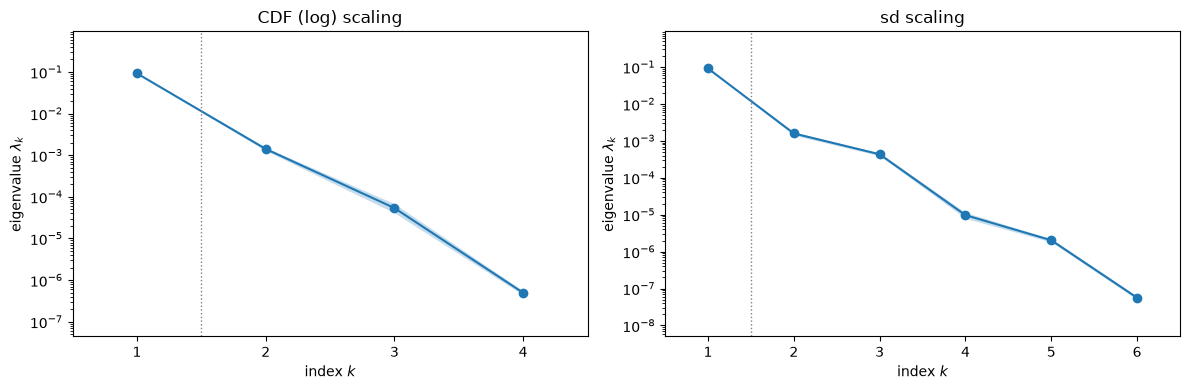

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, sub) in zip(axes, subs.items()):
    lam = sub.eigenvalues
    k0 = int(np.sum(np.abs(lam) > len(lam) * np.finfo(float).eps * lam[0]))
    ac.plotting.plot_eigenvalues(sub, ax=ax, k_max=k0)
    ax.set_title(name)
fig.tight_layout()
plt.close(fig)
for name, sub in subs.items():
    b = sub.bootstrap_eigenvalues
    r12, r23 = b[:, 0] / b[:, 1], b[:, 1] / b[:, 2]
    print(f'{name}: lambda_1 95 % bootstrap [{np.percentile(b[:, 0], 2.5):.4g}, {np.percentile(b[:, 0], 97.5):.4g}]; '
          f'lambda_1/lambda_2 2.5-97.5 % [{np.percentile(r12, 2.5):.1f}, {np.percentile(r12, 97.5):.1f}]; '
          f'lambda_2/lambda_3 [{np.percentile(r23, 2.5):.1f}, {np.percentile(r23, 97.5):.1f}]')
fig

With CDF scaling, $\lambda_1 = 0.09258$ (bootstrap interval $[0.09019, 0.09489]$), $\lambda_2 = 1.416\times10^{-3}$, $\lambda_3 = 5.395\times10^{-5}$ and $\lambda_4 = 4.965\times10^{-7}$; $\lambda_5$ and $\lambda_6$ are of order $10^{-34}$, the rounding error of the exact zeros above (the last two singular values of the normalized gradient matrix are of order $10^{-17}$ of the first, and the log gradients lie in the four-dimensional span to round-off). The ratios are $\lambda_1/\lambda_2 = 65.4$ (60.4–71.2 over the bootstrap replicates), $\lambda_2/\lambda_3 = 26.3$ (20.7–34.3) and $\lambda_3/\lambda_4 = 108.7$. The first direction carries 98.44 % of the trace and the first two 99.94 % (they leave out 1.56 % and 0.058 %). With sd scaling the leading eigenvalue is almost the same ($\lambda_1 = 0.09157$, $\lambda_1/\lambda_2 = 57.6$, 52.4–64.2), but the second gap is much smaller ($\lambda_2/\lambda_3 = 3.67$, 3.2–4.1), and the first two directions leave out 0.476 % of the trace. The scaling matters for the second direction, not for the first.

**Dimension.** The library's eigenvalue-gap rule picks $n = 1$ in both scalings, and one active variable is a good first description of $g$ (leave-one-out $R^2 = 0.98599$ for a quadratic in $y_1$, below). We choose $n = 2$ for the CDF-scaled analysis because $\lambda_2/\lambda_3 = 26.3$ is a second clear gap (its bootstrap range 20.7–34.3 stays far above 1), because a quadratic in $(y_1, y_2)$ raises the leave-one-out $R^2$ to 0.99933, and because the failure probability, the quantity this limit state exists for, is given to within 0.6 % by the two-variable quadratic and underestimated by 5.0 % with one variable (failure-probability section). With sd scaling $\lambda_2/\lambda_3 = 3.67$ gives no such support, and its two-variable quadratic has the lower $R^2 = 0.99619$.

CDF (log) scaling: bootstrap mean subspace distance, k = 1: 0.0034, k = 2: 0.0077, k = 3: 0.0031, k = 4: of order 1e-15 (round-off), k = 5: 0.11
sd scaling: bootstrap mean subspace distance, k = 1: 0.0043, k = 2: 0.022, k = 3: 0.0088, k = 4: 0.02, k = 5: 0.0063


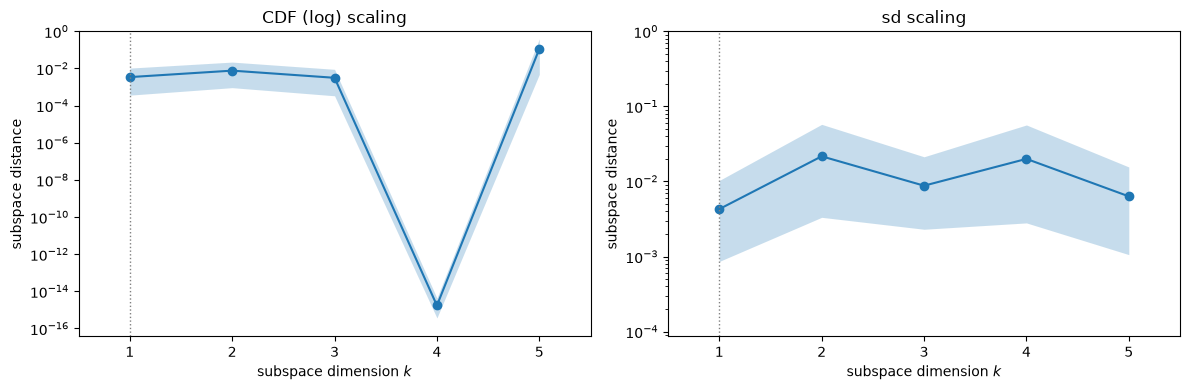

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, sub) in zip(axes, subs.items()):
    ac.plotting.plot_subspace_errors(sub, ax=ax)
    ax.set_title(name)
    dist = sub.bootstrap_distances.mean(axis=0)
    print(f'{name}: bootstrap mean subspace distance, ' +
          ', '.join(f'k = {k + 1}: ' + (f'{d:.2g}' if d > 1e-8 else f'of order {order(d)} (round-off)') for k, d in enumerate(dist)))
fig.tight_layout()
plt.close(fig)
fig

With CDF scaling the bootstrap mean subspace distance is 0.0034 for $n = 1$ and 0.0077 for $n = 2$, so both subspaces are well determined by 1000 samples; for $n = 4$ it is of order $10^{-15}$ (the four-dimensional span is exact) and for $n = 5$ it is 0.11, a value set by rounding that changes between platforms, because $\lambda_5 = \lambda_6 = 0$ makes the fifth direction arbitrary. With sd scaling the distances are 0.0043 for $n = 1$ and 0.022 for $n = 2$.

CDF (log) scaling: w1 = [ 0.0714  0.1656  0.0127  0.4905 -0.6372 -0.5663]
                   w2 = [-0.0302 -0.1497  0.0025  0.866   0.4118  0.2391]
sd scaling: w1 = [ 0.0716  0.1674  0.0128  0.4998 -0.6295 -0.5663]
            w2 = [ 0.0091 -0.0685 -0.0042  0.0031  0.659  -0.7489]
|w1(CDF) . w1(sd)| = 0.99993; |w2(CDF) . w2(sd)| = 0.1050


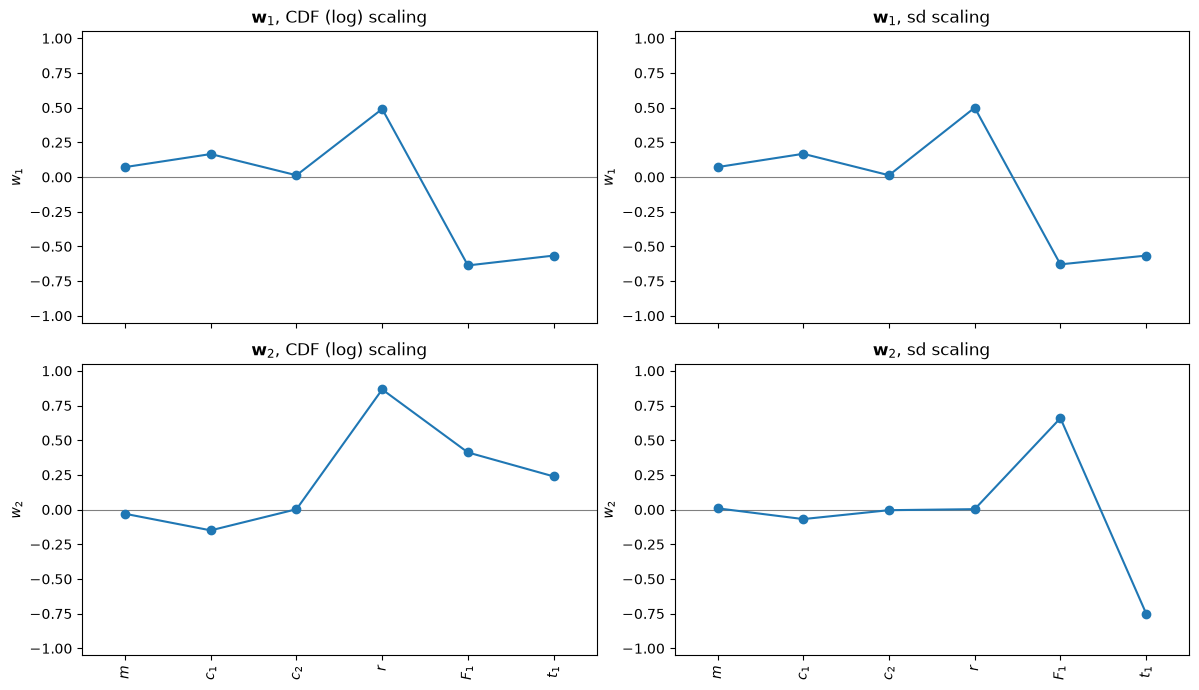

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for col, (name, sub) in enumerate(subs.items()):
    ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=labels, ax=[axes[0, col], axes[1, col]])
    axes[0, col].set_title(r'$\mathbf{w}_1$, ' + name)
    axes[1, col].set_title(r'$\mathbf{w}_2$, ' + name)
fig.tight_layout()
plt.close(fig)
for name, sub in subs.items():
    W = sub.W
    print(f'{name}: w1 = {np.array2string(W[:, 0], precision=4)}')
    print(f'{" " * len(name)}  w2 = {np.array2string(W[:, 1], precision=4)}')
print(f'|w1(CDF) . w1(sd)| = {abs(sub_cdf.W[:, 0] @ sub_sd.W[:, 0]):.5f}; |w2(CDF) . w2(sd)| = {abs(sub_cdf.W[:, 1] @ sub_sd.W[:, 1]):.4f}')
fig

**Eigenvectors.** With CDF scaling, $g$ increases along $\mathbf w_1 = (0.0714, 0.1656, 0.0127, 0.4905, -0.6372, -0.5663)$ in the order $(m, c_1, c_2, r, F_1, t_1)$: the pulse load and its duration lower the safety margin, the yield displacement (which sets the threshold $3r$) raises it, and a stiffer spring $c_1$ raises it a little; $m$ and $c_2$ hardly matter. $\mathbf w_2 = (-0.0302, -0.1497, 0.0025, 0.866, 0.4118, 0.2391)$ is mostly $r$ against the load: it separates the threshold from the displacement, which enters $g$ nonlinearly. With sd scaling $\mathbf w_1$ is nearly the same ($|\mathbf w_1^{\mathrm{CDF}}\cdot\mathbf w_1^{\mathrm{sd}}| = 0.99993$), but $\mathbf w_2 = (0.0091, -0.0685, -0.0042, 0.0031, 0.659, -0.7489)$ is a contrast of $F_1$ against $t_1$, almost orthogonal to the CDF-scaled $\mathbf w_2$ ($|\mathbf w_2^{\mathrm{CDF}}\cdot\mathbf w_2^{\mathrm{sd}}| = 0.1050$). The two scalings weight each gradient by $s_i x_i$ and by $\mathrm{sd}_i$, which differ most for the inputs with the largest spread ($F_1$, $t_1$, CoV 0.2), and the small eigenvalues $\lambda_2$, $\lambda_3$ are sensitive to that weighting.

y1 in [-3.13, 3.05]; corr(y1, g) = 0.98702
failures (g <= 0) at y1 in [-3.13, -1.60]; safe samples with y1 below the largest failing y1: 34


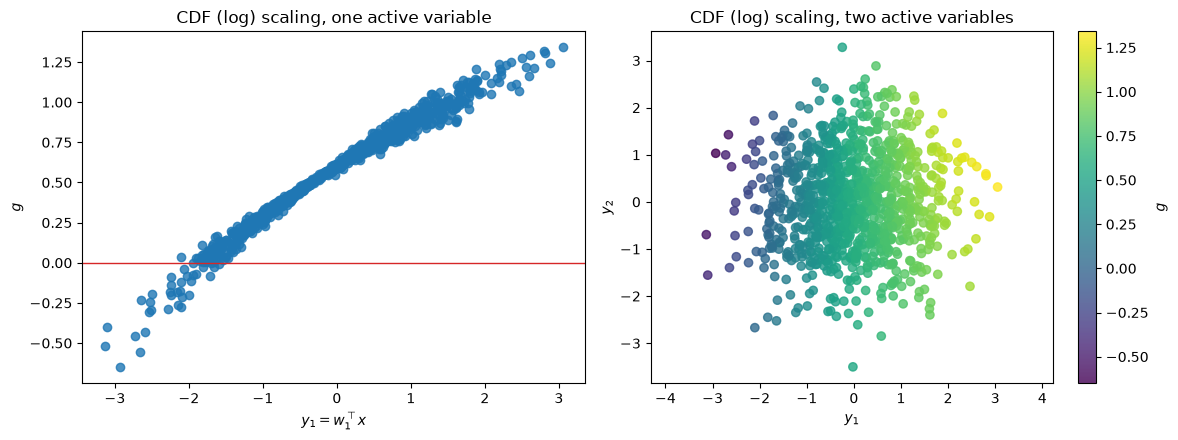

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ac.plotting.plot_sufficient_summary(sub_cdf, X=Z, f=g, dims=1, qoi_label=r'$g$', ax=axes[0])
axes[0].axhline(0, color='C3', lw=1)
axes[0].set_title('CDF (log) scaling, one active variable')
ac.plotting.plot_sufficient_summary(ac.with_dimension(sub_cdf, 2), X=Z, f=g, dims=2, qoi_label=r'$g$', ax=axes[1])
axes[1].set_title('CDF (log) scaling, two active variables')
fig.tight_layout()
plt.close(fig)
Y = space_cdf.to_normalized(Z) @ sub_cdf.W[:, :2]
print(f'y1 in [{Y[:, 0].min():.2f}, {Y[:, 0].max():.2f}]; corr(y1, g) = {np.corrcoef(Y[:, 0], g)[0, 1]:.5f}')
fail = g <= 0
print(f'failures (g <= 0) at y1 in [{Y[fail, 0].min():.2f}, {Y[fail, 0].max():.2f}]; '
      f'safe samples with y1 below the largest failing y1: {int(((~fail) & (Y[:, 0] < Y[fail, 0].max())).sum())}')
fig

The one-variable summary plot (left; the red line is $g = 0$) shows a tight, slightly curved trend, $\mathrm{corr}(y_1, g) = 0.98702$, with $y_1 \in [-3.13, 3.05]$. The 33 failures lie at $y_1 \in [-3.13, -1.60]$, and 34 safe samples have $y_1$ below the largest failing $y_1$: near $g = 0$ the spread about the trend decides failure, and in the two-variable plot (right) that spread is ordered along $y_2$.

linear, n = 1     LOO R^2 = 0.97398
quadratic, n = 1  LOO R^2 = 0.98599
cubic, n = 1      LOO R^2 = 0.98595
quadratic, n = 2  LOO R^2 = 0.99933
cubic, n = 2      LOO R^2 = 0.99968
sd scaling, quadratic, n = 1  LOO R^2 = 0.98812
sd scaling, quadratic, n = 2  LOO R^2 = 0.99619


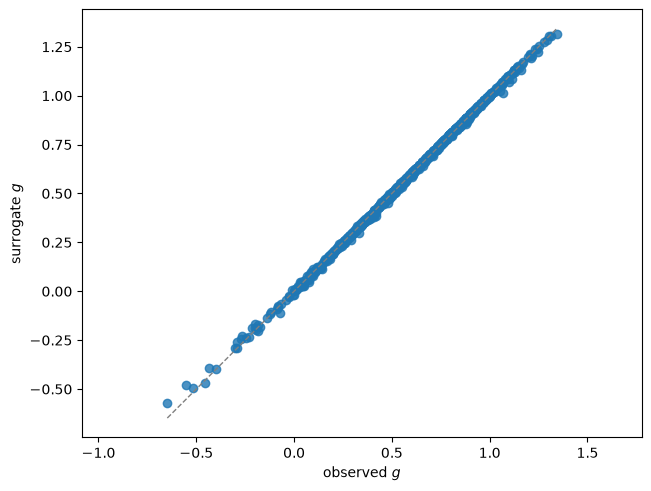

In [10]:
surs = {}
for name, sub_k, deg in [('linear, n = 1', sub_cdf, 1), ('quadratic, n = 1', sub_cdf, 2),
                         ('cubic, n = 1', sub_cdf, 3), ('quadratic, n = 2', ac.with_dimension(sub_cdf, 2), 2),
                         ('cubic, n = 2', ac.with_dimension(sub_cdf, 2), 3)]:
    s = ac.fit_surrogate(X=Z, f=g, subspace=sub_k, kind='poly', degree=deg)
    surs[name] = s
    print(f'{name:17s} LOO R^2 = {s.loo_r_squared:.5f}')
for name, sub_k in [('sd scaling, quadratic, n = 1', sub_sd), ('sd scaling, quadratic, n = 2', ac.with_dimension(sub_sd, 2))]:
    print(f'{name:29s} LOO R^2 = {ac.fit_surrogate(X=X, f=g, subspace=sub_k, kind="poly", degree=2).loo_r_squared:.5f}')
fig, ax = ac.plotting.plot_surrogate_fit(surs['quadratic, n = 2'], X=Z, f=g, qoi_label=r'$g$')
plt.close(fig)
fig

#### Surrogates on the active variables

A line in $y_1$ has leave-one-out $R^2 = 0.97398$, a quadratic 0.98599 and a cubic 0.98595 (no gain from the cubic); in $(y_1, y_2)$ a quadratic has 0.99933 and a cubic 0.99968 (the figure shows the two-variable quadratic). With sd scaling the quadratics have 0.98812 ($n = 1$) and 0.99619 ($n = 2$).

### Failure probability

The paper's purpose for this example is the failure probability $P_f = P[g \le 0]$. We estimate it for the yielding oscillator by plain Monte Carlo with 95 % Wilson intervals: $4\times10^6$ draws of the paper's lognormal inputs and $10^6$ draws of UQTestFuns's normal inputs (draws with a non-positive input, outside physical meaning, are dropped and counted). We compare with the paper's importance-sampling value and Bucher et al.'s adaptive-sampling value (p. 218), which have no stated sampling errors; for scale only, the cell prints the standard deviation that a plain Monte Carlo estimate with the same number of runs would have. Then we evaluate the surrogates above on $10^6$ fresh lognormal draws and compare with the model on the same draws.

In [11]:
t0 = time.perf_counter()
P_PAPER, P_BUCHER = 3.99864e-2, 3.81e-2          # p. 218
pf = {}
for name, sampler, N_PF, seed in [('lognormal (paper, Table 7)', om.sample_lognormal, 4 * 10 ** 6, SEED + 3),
                                  ('normal (UQTestFuns Gayton2003)', om.sample_normal, 10 ** 6, SEED + 4)]:
    p, nf, N, (lo, hi), nd = om.failure_probability(sampler, N_PF, np.random.default_rng(seed), positive_only=True)
    pf[name] = (p, lo, hi)
    print(f'yielding oscillator, {name:31s}: {nf} failures in {N} draws ({nd} dropped with an input <= 0), '
          f'Pf = {p:.4e}, 95 % interval [{lo:.4e}, {hi:.4e}]')
p_ln, lo_ln, hi_ln = pf['lognormal (paper, Table 7)']
for ref, val in (('paper, importance sampling, 1000 runs', P_PAPER), ('Bucher et al., adaptive sampling, 1500 runs', P_BUCHER)):
    print(f'   {ref}: {val:.4e}; notebook / reference - 1 = {100 * (p_ln / val - 1):+.1f} %; '
          f'reference inside the 95 % interval: {lo_ln <= val <= hi_ln}')
for n_ref, val in ((1000, P_PAPER), (1500, P_BUCHER)):
    sd_ref = np.sqrt(p_ln * (1 - p_ln) / n_ref)
    print(f'   for scale: sd of a plain Monte Carlo estimate with {n_ref} draws at Pf = {p_ln:.4f}: {sd_ref:.4f}; '
          f'|reference - notebook| = {abs(val - p_ln):.4f} = {abs(val - p_ln) / sd_ref:.2f} of that sd')
# surrogates in the active variables on fresh lognormal draws, against the model on the same draws
Xs = om.sample_lognormal(10 ** 6, np.random.default_rng(SEED + 5))
gs = om.limit_state(Xs)
nf_true = int((gs <= 0).sum())
print(f'model on 10^6 fresh lognormal draws: Pf = {nf_true / len(Xs):.4e}')
for name in ('quadratic, n = 1', 'cubic, n = 1', 'quadratic, n = 2', 'cubic, n = 2'):
    gsur = ac.surrogates.predict(surs[name], np.log(Xs))
    nf_s = int((gsur <= 0).sum())
    lo, hi = wilson(nf_s, len(Xs))
    wrong = np.mean((gsur <= 0) != (gs <= 0))
    print(f'surrogate {name:17s}: Pf = {nf_s / len(Xs):.4e} [{lo:.4e}, {hi:.4e}]; '
          f'surrogate/model - 1 = {100 * (nf_s / nf_true - 1):+.1f} %; misclassified {100 * wrong:.3f} %')
print(f'{time.perf_counter() - t0:.0f} s')

yielding oscillator, lognormal (paper, Table 7)     : 153148 failures in 4000000 draws (0 dropped with an input <= 0), Pf = 3.8287e-02, 95 % interval [3.8099e-02, 3.8475e-02]


yielding oscillator, normal (UQTestFuns Gayton2003) : 34710 failures in 999998 draws (2 dropped with an input <= 0), Pf = 3.4710e-02, 95 % interval [3.4353e-02, 3.5071e-02]
   paper, importance sampling, 1000 runs: 3.9986e-02; notebook / reference - 1 = -4.2 %; reference inside the 95 % interval: False
   Bucher et al., adaptive sampling, 1500 runs: 3.8100e-02; notebook / reference - 1 = +0.5 %; reference inside the 95 % interval: True
   for scale: sd of a plain Monte Carlo estimate with 1000 draws at Pf = 0.0383: 0.0061; |reference - notebook| = 0.0017 = 0.28 of that sd
   for scale: sd of a plain Monte Carlo estimate with 1500 draws at Pf = 0.0383: 0.0050; |reference - notebook| = 0.0002 = 0.04 of that sd


model on 10^6 fresh lognormal draws: Pf = 3.8373e-02
surrogate quadratic, n = 1 : Pf = 3.6448e-02 [3.6082e-02, 3.6817e-02]; surrogate/model - 1 = -5.0 %; misclassified 1.033 %


surrogate cubic, n = 1     : Pf = 3.6476e-02 [3.6110e-02, 3.6845e-02]; surrogate/model - 1 = -4.9 %; misclassified 1.032 %


surrogate quadratic, n = 2 : Pf = 3.8128e-02 [3.7754e-02, 3.8505e-02]; surrogate/model - 1 = -0.6 %; misclassified 0.170 %


surrogate cubic, n = 2     : Pf = 3.8198e-02 [3.7824e-02, 3.8575e-02]; surrogate/model - 1 = -0.5 %; misclassified 0.133 %
35 s


With the paper's lognormal inputs the yielding oscillator gives $P_f = 3.8287\times10^{-2}$ (153 148 failures in $4\times10^6$ draws, 95 % interval $[3.8099, 3.8475]\times10^{-2}$); `check_accuracy.py` (check 7) gives $3.8226\times10^{-2}$, $[3.8107, 3.8345]\times10^{-2}$, with $10^7$ other draws. Bucher et al.'s $3.81\times10^{-2}$ lies inside the interval (our estimate is 0.5 % above it). The paper's $3.99864\times10^{-2}$ lies outside it (our estimate is 4.2 % below it); the paper gives no interval, but a plain Monte Carlo estimate from 1000 runs would have a standard deviation of 0.0061 at this $P_f$, and the difference, 0.0017, is 0.28 of that, so it is well within what a 1000-run sampling estimate can resolve (how much the paper's importance-sampling density reduced that error is not stated). With UQTestFuns's normal inputs the yielding oscillator gives $3.4710\times10^{-2}$ ($[3.4353, 3.5071]\times10^{-2}$; 2 of $10^6$ draws dropped).

On $10^6$ fresh lognormal draws, where the model gives $3.8373\times10^{-2}$, the quadratic in $y_1$ gives $3.6448\times10^{-2}$ (5.0 % low) and the cubic $3.6476\times10^{-2}$ (4.9 % low), both intervals below the model's value, misclassifying 1.033 % and 1.032 % of the draws; the quadratic in $(y_1, y_2)$ gives $3.8128\times10^{-2}$ ($[3.7754, 3.8505]\times10^{-2}$, 0.6 % low, an interval that contains the model's value) and misclassifies 0.170 %, the cubic 0.5 % low and 0.133 %.

### Secondary study: the linear closed form

The closed-form benchmark $g_{\mathrm{lin}} = 3r - |z_{\mathrm{lin}}|$ on the same 1000 samples (exact closed-form gradients in `gradients_linear.csv`), with the same scalings and seed; and its failure probability with $10^7$ draws of the lognormal and of the normal inputs, the same seeds as above. This is the function that UQTestFuns and the later benchmark literature call the undamped oscillator; it is not the paper's model.

In [12]:
t0 = time.perf_counter()
Gz_lin = G_lin * X
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    sub_lin = ac.active_subspace(space=space_cdf, X=Z, f=g_lin, grads=Gz_lin, estimator='as', nboot=500, rng=SEED)
    sub_lin_sd = ac.active_subspace(space=space_sd, X=X, f=g_lin, grads=G_lin, estimator='as', nboot=500, rng=SEED)
sub_lin = ac.orient(sub_lin, by='covariance', X=Z, f=g_lin, columns=2)
sub_lin_sd = ac.orient(sub_lin_sd, by='covariance', X=X, f=g_lin, columns=2)
for name, sub in (('linear closed form, CDF scaling', sub_lin), ('linear closed form, sd scaling', sub_lin_sd)):
    lam = sub.eigenvalues
    tol = len(lam) * np.finfo(float).eps * lam[0]
    k0 = int(np.sum(np.abs(lam) > tol))
    msg = f'{name}: eigenvalues {np.array2string(lam[:k0], precision=4)}'
    msg += ''.join(f', lambda_{k + 1} of order {order(lam[k])}' for k in range(k0, len(lam)))
    print(msg + f' (round-off level is m eps lambda_1 = {tol:.0e})')
    print(f'   ratios lambda_k/lambda_k+1 (k < {k0}): {np.array2string(lam[:k0 - 1] / lam[1:k0], precision=3)}')
print(f'linear closed form, CDF scaling: w1 = {np.array2string(sub_lin.W[:, 0], precision=4)}')
print(f'|w1(linear) . w1(yielding)| = {abs(sub_lin.W[:, 0] @ sub_cdf.W[:, 0]):.5f}; '
      f'distance between the two-dimensional subspaces = {np.linalg.norm(sub_lin.W[:, :2] @ sub_lin.W[:, :2].T - sub_cdf.W[:, :2] @ sub_cdf.W[:, :2].T, 2):.4f}')
for name, sub_k in (('n = 1', sub_lin), ('n = 2', ac.with_dimension(sub_lin, 2))):
    print(f'linear closed form, quadratic, {name}: LOO R^2 = {ac.fit_surrogate(X=Z, f=g_lin, subspace=sub_k, kind="poly", degree=2).loo_r_squared:.5f}')
print(f'corr(g, g_lin) on the design = {np.corrcoef(g, g_lin)[0, 1]:.5f}; g - g_lin in [{(g - g_lin).min():.4f}, {(g - g_lin).max():.4f}]')
pf_lin = {}
for name, sampler, seed in [('lognormal (paper, Table 7)', om.sample_lognormal, SEED + 3),
                            ('normal (UQTestFuns Gayton2003)', om.sample_normal, SEED + 4)]:
    p, nf, N, (lo, hi), _ = om.failure_probability(sampler, 10 ** 7, np.random.default_rng(seed), chunk=10 ** 6,
                                                   model=om.limit_state_linear)
    pf_lin[name] = (p, lo, hi)
    print(f'linear closed form, {name:31s}: {nf} failures in {N:.0e} draws, Pf = {p:.4e}, 95 % interval [{lo:.4e}, {hi:.4e}]')
p_n = pf_lin['normal (UQTestFuns Gayton2003)'][0]
print(f'linear, normal inputs: Pf / Echard et al. 2011 2.834e-2 - 1 = {100 * (p_n / 2.834e-2 - 1):+.1f} %; '
      f'linear / yielding Pf (lognormal) - 1 = {100 * (pf_lin["lognormal (paper, Table 7)"][0] / p_ln - 1):+.1f} %')
print(f'{time.perf_counter() - t0:.0f} s')

linear closed form, CDF scaling: eigenvalues [8.7106e-02 1.3222e-03 5.2562e-05 6.7303e-07], lambda_5 of order 1e-35, lambda_6 of order 1e-35 (round-off level is m eps lambda_1 = 1e-16)
   ratios lambda_k/lambda_k+1 (k < 4): [65.879 25.155 78.097]
linear closed form, sd scaling: eigenvalues [8.6456e-02 1.4888e-03 3.8105e-04 8.0011e-06 1.8761e-06], lambda_6 of order 1e-36 (round-off level is m eps lambda_1 = 1e-16)
   ratios lambda_k/lambda_k+1 (k < 5): [58.072  3.907 47.625  4.265]
linear closed form, CDF scaling: w1 = [ 0.071   0.1611  0.0163  0.4997 -0.6339 -0.5632]
|w1(linear) . w1(yielding)| = 0.99993; distance between the two-dimensional subspaces = 0.0246
linear closed form, quadratic, n = 1: LOO R^2 = 0.98617
linear closed form, quadratic, n = 2: LOO R^2 = 0.99935
corr(g, g_lin) on the design = 0.99993; g - g_lin in [-0.0571, 0.0000]


linear closed form, lognormal (paper, Table 7)     : 323104 failures in 1e+07 draws, Pf = 3.2310e-02, 95 % interval [3.2201e-02, 3.2420e-02]


linear closed form, normal (UQTestFuns Gayton2003) : 285306 failures in 1e+07 draws, Pf = 2.8531e-02, 95 % interval [2.8428e-02, 2.8634e-02]
linear, normal inputs: Pf / Echard et al. 2011 2.834e-2 - 1 = +0.7 %; linear / yielding Pf (lognormal) - 1 = -15.6 %
4 s


The linear closed form has the same structure: with CDF scaling $\lambda_1/\lambda_2 = 65.9$, $\lambda_2/\lambda_3 = 25.2$, $\lambda_3/\lambda_4 = 78.1$ and two round-off eigenvalues (here $z_{\mathrm{lin}}/r$ depends on the inputs through $F_1/(kr)$ and $t_1\sqrt{k/m}$ with $k = c_1 + c_2$, again four log combinations), and with sd scaling 58.072, 3.907, 47.625 and 4.265 and one round-off eigenvalue, the exact zero ($\partial g_{\mathrm{lin}}/\partial c_1 = \partial g_{\mathrm{lin}}/\partial c_2$). Its $\mathbf w_1 = (0.071, 0.1611, 0.0163, 0.4997, -0.6339, -0.5632)$ matches the yielding oscillator's to $|\mathbf w_1\cdot\mathbf w_1| = 0.99993$, and the two-dimensional subspaces are 0.0246 apart; the quadratics in its active variables have leave-one-out $R^2$ 0.98617 ($n = 1$) and 0.99935 ($n = 2$). On the design $g$ and $g_{\mathrm{lin}}$ are correlated at 0.99993 and $g - g_{\mathrm{lin}} \in [-0.0571, 0]$: yielding lowers the margin but hardly changes its directions.

The failure probabilities differ more. With the lognormal inputs the linear closed form gives $3.2310\times10^{-2}$ ($[3.2201, 3.2420]\times10^{-2}$), 15.6 % below the yielding oscillator; with UQTestFuns's normal inputs it gives $2.8531\times10^{-2}$ ($[2.8428, 2.8634]\times10^{-2}$), 0.7 % above the Monte Carlo value $2.834\times10^{-2}$ (CoV 2.2 %) of Echard et al. [[6]](https://doi.org/10.1016/j.strusafe.2011.01.002), Table 6, as UQTestFuns lists it, which therefore refers to the linear closed form, not to the paper's yielding oscillator.

### Comparison with the paper

The paper [[1]](https://doi.org/10.1016/0167-4730(93)90003-J) does not compute an active subspace or gradients; it fits quadratic response surfaces iteratively and reports failure probabilities (pp. 218–219, Tables 8 and 9). Its reference value and Bucher et al.'s come from simulations of the nonlinear dynamic response, the model this notebook solves (with the reading of Fig. 10 stated above). The normal-input reference values are those UQTestFuns lists [[3]](https://doi.org/10.21105/joss.05671) (from Echard et al. [[6]](https://doi.org/10.1016/j.strusafe.2011.01.002), Table 6, and [[7]](https://doi.org/10.1016/j.ress.2012.10.008), Table 5; those papers were not read for this notebook); they belong to the linear closed form. The values for UQTestFuns's two reduced pulse loads come from `check_accuracy.py` (check 6), not from this notebook.

| Quantity | Paper or reference value (source) | Notebook value |
|---|---|---|
| $P_f$, lognormal inputs | $3.99864\times10^{-2}$, importance sampling, 1000 simulations of the nonlinear dynamic response (p. 218; Tables 8, 9), no interval given | yielding oscillator, Monte Carlo $4\times10^6$: $3.8287\times10^{-2}$, $[3.8099, 3.8475]\times10^{-2}$ (4.2 % below); `check_accuracy.py`, $10^7$: $3.8226\times10^{-2}$, $[3.8107, 3.8345]\times10^{-2}$ |
| $P_f$, lognormal inputs, Bucher et al. | $3.81\times10^{-2}$, adaptive sampling, 1500 simulations (p. 218, text) | inside the interval above (0.5 % below our estimate) |
| $P_f$, response surfaces of Bucher et al. | $3.01\times10^{-2}$ and $3.67\times10^{-2}$, without and with cross terms (p. 218, text) | not computed (methods of the paper) |
| $P_f$, Approach A-0 of the paper | $2.61898$, $4.09679$, $3.93365\times10^{-2}$ over three iterations (Table 8, p. 218); first-iteration variants $3.22473$, $3.42005$, $3.40402\times10^{-2}$ (Table 9, p. 219) | not computed (methods of the paper) |
| $P_f$, lognormal inputs, linear closed form | not in the paper | $3.2310\times10^{-2}$, $[3.2201, 3.2420]\times10^{-2}$, Monte Carlo $10^7$ |
| $P_f$, normal inputs (UQTestFuns "Gayton2003"), linear closed form | $2.834\times10^{-2}$, Monte Carlo $7\times10^4$, CoV 2.2 % ([[6]](https://doi.org/10.1016/j.strusafe.2011.01.002) Table 6, as listed by UQTestFuns) | $2.8531\times10^{-2}$, $[2.8428, 2.8634]\times10^{-2}$, Monte Carlo $10^7$ |
| $P_f$, normal inputs, yielding oscillator | not reported | $3.4710\times10^{-2}$, $[3.4353, 3.5071]\times10^{-2}$, Monte Carlo $10^6$ |
| $P_f$, linear closed form, $F_1 \sim N(0.6, 0.1)$ | $9.09\times10^{-6}$ (MCS $1.8\times10^8$, CoV 2.47 %); FORM $9.76\times10^{-6}$ ([[7]](https://doi.org/10.1016/j.ress.2012.10.008) Table 5, via UQTestFuns) | `check_accuracy.py`: FORM $9.759\times10^{-6}$; importance sampling $9.112\times10^{-6} \pm 4.1\times10^{-8}$; Monte Carlo $10^8$: $8.910\times10^{-6}$, $[8.344, 9.515]\times10^{-6}$ |
| $P_f$, linear closed form, $F_1 \sim N(0.45, 0.075)$ | $1.55\times10^{-8}$ (MCS $9\times10^8$, CoV 2.68 %); FORM $1.56\times10^{-8}$ ([[7]](https://doi.org/10.1016/j.ress.2012.10.008) Table 5, via UQTestFuns) | `check_accuracy.py`: FORM $1.562\times10^{-8}$; importance sampling $1.510\times10^{-8} \pm 8.0\times10^{-11}$ |
| Active subspace | not reported | yielding oscillator, CDF scaling, $n = 2$: $\lambda_1/\lambda_2 = 65.4$, $\lambda_2/\lambda_3 = 26.3$; LOO $R^2$ 0.98599 ($n = 1$), 0.99933 ($n = 2$) |

The yielding oscillator reproduces Bucher et al.'s adaptive-sampling value within our 95 % interval and lies 4.2 % below the paper's importance-sampling value, a difference of 0.28 standard deviations of a 1000-run plain Monte Carlo estimate (neither value comes with a stated error). The linear closed form, which does not model the yielding of spring 2, gives a failure probability 15.6 % lower than the yielding oscillator with the same inputs: yielding increases the peak displacement in 974 of the 1000 samples, so the larger $P_f$ of the paper's model is a computed result here. The remaining modelling choices (a perfectly plastic spring 2, symmetric yield in compression, moments of $x$ in Table 7) are listed in `DATA.md` as open questions; the second does not affect $z_{\max}$.

### References

[1] M. R. Rajashekhar and B. R. Ellingwood. [A new look at the response surface approach for reliability analysis](https://doi.org/10.1016/0167-4730(93)90003-J). *Structural Safety*, 12(3):205–220, 1993.

[2] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, 2015.

[3] D. Wicaksono and M. Hecht. [UQTestFuns: A Python3 library of uncertainty quantification (UQ) test functions](https://doi.org/10.21105/joss.05671). *Journal of Open Source Software*, 8(90):5671, 2023. Version 0.7.0 (MIT licence), `UndampedOscillator`; documentation page "Undamped Oscillator Reliability Problem".

[4] C. G. Bucher and U. Bourgund. [A fast and efficient response surface approach for structural reliability problems](https://doi.org/10.1016/0167-4730(90)90012-E). *Structural Safety*, 7(1):57–66, 1990.

[5] N. Gayton, J. M. Bourinet, and M. Lemaire. [CQ2RS: a new statistical approach to the response surface method for reliability analysis](https://doi.org/10.1016/S0167-4730(02)00045-0). *Structural Safety*, 25(1):99–121, 2003.

[6] B. Echard, N. Gayton, and M. Lemaire. [AK-MCS: An active learning reliability method combining Kriging and Monte Carlo Simulation](https://doi.org/10.1016/j.strusafe.2011.01.002). *Structural Safety*, 33(2):145–154, 2011.

[7] B. Echard, N. Gayton, M. Lemaire, and N. Relun. [A combined Importance Sampling and Kriging reliability method for small failure probabilities with time-demanding numerical models](https://doi.org/10.1016/j.ress.2012.10.008). *Reliability Engineering & System Safety*, 111:232–240, 2013.

### Acknowledgments

From [[1]](https://doi.org/10.1016/0167-4730(93)90003-J) (pp. 219–220): the first author "expresses grateful acknowledgement to the Council for International Exchange of Scholars, Washington D.C., for sponsoring his research at the Johns Hopkins University."

In [13]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 44.6 s
